# 134 · good results: decres-rescale-aug10-v1@300
transformer4 `--decoder res --latent-norm rescale`, all four augmentations at p = .1, 300 ep. Twelve hand-picked samples (`SAMPLES`), shown as ground-truth photo | predicted mask pairs.

Predictions are the run's saved ep300 outputs (outputs_history, eval splits + train-set eval). The run trained with `--compile 0`, so these are eager fp32 evals (no compile-eval bias), the same source nb132/nb133 use.

In [1]:
BG_SAT, BG_DIM = 0.6, 1.0   # true.png: background saturation (0 = gray, 1 = original) and brightness; the object stays full color
SHOW_THUMBS, THUMB_FRAC = False, 0.3   # figure: reference photo of each true object (OBJ_DIR/<name>.png|jpg|jpeg) inset bottom-right of the GT photo, height = THUMB_FRAC x photo height
OBJ_DIR = "assets/objects"           # relative to the repo root
THUMB_TOL = 0.08                     # opaque reference photos: pixels within this RGB distance of the border colour, connected to the border, become transparent
N_PER_ROW = 3              # pairs per figure row (wraps)
SAMPLE_BG = "#e6e6e6"      # figure: one card behind each sample pair (letterbox margins + the gap between photo and mask)
MASK_BG, MASK_FG = "#464646", "white"   # mask panels: colour at p = 0 / object (blended by the binary or soft mask value)
TAG_FS = 18
MASK_BINARY = True         # mask panels: p > .08 binary (False = soft prob)
OUT = "plots/nb134_samples"   # per-sample PNGs + samples.csv, relative to notebooks/ (any folder works)
RUN, EP = "decres-rescale-aug10-v1", 300
SCALE = 0.25    # photos at 1/4 of the cropped overhead
# figure samples, in order: (label, "<position_id>-<speaker>"); the box is found from the id (position ids are per box dataset)
SAMPLES = [("in-distribution: cube", "41-3"), ("in-distribution: candle", "3909-1"), ("in-distribution: soap dispenser", "1760-1"), ("in-distribution: vase", "3322-5"),
           ("multi-object: cube and vase", "2799-7"), ("multi-object: two cubes", "1149-1"), ("unseen object: coffee pot", "1866-5"), ("unseen object: tomato sauce", "4481-5"),
           ("unseen rotation: soap dispenser", "4541-1"), ("unseen position: vase", "463-1"), ("unseen speaker: vase", "4703-4"), ("unseen speckle: cube", "2884-3")]

In [2]:
import sys, glob
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from sklearn.cluster import KMeans

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits
from score import truth
from utils import THR   # .08, the iou08 threshold
PLOTS = ROOT / "notebooks/plots"

samples, idxs = load_splits()
dirs, metas = list(samples), list(samples.values())
SPLIT = {i: n for n, ids in idxs.items() for i in ids}                       # meta index -> "train" | "eval/<box>/<split>"
AT = {(m["box"], m["position_id"], m["speaker"]): i for i, m in enumerate(metas)}
KEY = {(m["experiment"], m["position_id"], m["speaker"]): i for i, m in enumerate(metas)}
BOXES = sorted({m["box"] for m in metas})                                      # = info["boxes"], the box head's class order
def obj_name(m): return "+".join(sorted(m["objects"]))
def sid(m): return int(m["sample_id"]) if m["sample_id"].isdigit() else -1   # truth() / saved info: -1 for "<pos>-<spk>" dirs

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

## Saved predictions
Every saved ep300 batch: eval splits + the train-set eval (model in eval mode, no augmentation). Keyed by (experiment, position, speaker).

In [3]:
PRED = {}   # (experiment, position, speaker) -> (mask (64,64), object logits, box logits)
for f in sorted(glob.glob(str(ROOT / f"runs/{RUN}/outputs_history/eval/*/*/ep{EP:04d}-*.pt"))) + sorted(glob.glob(str(ROOT / f"runs/{RUN}/outputs_history/train/ep{EP:04d}-*.pt"))):
    d = torch.load(f, weights_only=False, map_location="cpu")
    CLASSES = d["objects"][:-1]                                                # object head classes ("" = empty); "unseen" has no logit
    for p, o, b, e, pos, spk in zip(d["mask_pred"].float().numpy(), d["object_logits"].float(), d["box_logits"].float(), d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()):
        PRED[e, pos, spk] = (p, o.numpy(), b.numpy())
print(len(PRED), "predictions · object classes:", CLASSES, "· boxes:", BOXES)

# box head sanity over every saved prediction: argmax vs the true box (checks BOXES is the head's order)
ok = [BOXES[b.argmax()] == metas[KEY[k]]["box"] for k, (_, _, b) in PRED.items()]
print(f"box head accuracy over all saved samples: {np.mean(ok):.4f}")

15891 predictions · object classes: ['', 'candle', 'cylinder-1000g', 'cylinder-100g', 'cylinder-200g', 'cylinder-500g', 'glass-cup', 'green-cube+red-cube', 'red-cube', 'red-cube+vase', 'soap dispenser', 'vase'] · boxes: ['cardboard', 'gastronorm', 'green-plastic']
box head accuracy over all saved samples: 0.9977


## Prediction per sample (no ground truth)
- **box** = argmax of the box head.
- **object identity and count** = argmax of the object head. Its classes are the object combinations seen in train, so the count is the number of objects in that class (`""` = empty box, 0 objects). transformer4 has no separate count or CoM head.
- **CoM** = from the predicted mask b = p > .08: the k = count largest connected components, CoM weighted by p. If b has fewer than k components, k-means on its pixels instead. With 2+ objects the object-to-CoM pairing is arbitrary (nothing in the model says which blob is which).

Ground truth is used only to score (IoU, CoM distance) and for the GT panels.

In [4]:
RR, CC = np.mgrid[:64, :64].astype(np.float64)

def predict(p, o, b):
    """-> (box, [objects], (k,2) CoMs as box fractions (row, col)): model outputs only"""
    box, cls = BOXES[b.argmax()], CLASSES[o.argmax()]
    objs = cls.split("+") if cls else []
    k, m = len(objs), p > THR
    if k == 0 or not m.any(): return box, objs, np.zeros((0, 2))
    lab, n = ndimage.label(m)
    if n >= k:
        big = np.argsort(np.bincount(lab.ravel())[1:])[::-1][:k] + 1
        c = np.array([[(p * RR)[lab == j].sum(), (p * CC)[lab == j].sum()] / p[lab == j].sum() for j in big])
    else:
        px = np.argwhere(m)
        c = KMeans(k, n_init=4, random_state=0).fit(px, sample_weight=p[m]).cluster_centers_
    return box, objs, (c + 0.5) / 64

def iou08(p, y): return ((p > THR) & y).sum() / max(((p > THR) | y).sum(), 1)

## The samples
`(label, pos-spk)` in figure order. Position ids are per box dataset, so each id is looked up in every box and must match exactly one sample (else flagged). Unseen objects (coffee pot, tomato sauce) have no object-head class, so `object_ok` cannot be true for them.

In [5]:
def row(i):
    """one sample -> table row; model outputs only for pred_*; com_dist_px = mean over true objects of the distance to the nearest predicted CoM (64x64 px)"""
    m = metas[i]
    k = (m["experiment"], m["position_id"], m["speaker"])
    assert k in PRED, f"{k}: no saved prediction (needs an eager checkpoint run)"
    p, o, b = PRED[k]
    y = truth(m["experiment"], sid(m), m["position_id"], m["speaker"], 64, 64) > 0.5
    box, objs, pc = predict(p, o, b)
    H, W = m["crop_overhead_shape"][:2]
    tc = np.array([[c[0][0] / H, c[0][1] / W] for c in m["coms"]]).reshape(-1, 2)   # true CoMs, box fractions
    d = np.mean([np.min(np.linalg.norm((pc - t) * 64, axis=1)) for t in tc]) if len(pc) and len(tc) else np.nan
    return dict(id=f"{m['position_id']}-{m['speaker']}", sample=m["sample_id"], split=SPLIT.get(i, "excluded"), true_box=m["box"], pred_box=box,
                true_object=obj_name(m) or "(empty)", pred_object="+".join(objs) or "(empty)", pred_count=len(objs),
                true_com=np.round(tc * 64, 1).tolist(), pred_com=np.round(pc * 64, 1).tolist(), com_dist_px=round(float(d), 2), iou08=round(float(iou08(p, y)), 3))

# position ids are numbered per box dataset: look each id up in every box; it must match exactly one sample
rows, SHOW = [], []   # SHOW: (label, meta index) in figure order
for label, name in SAMPLES:
    pos, spk = map(int, name.split("-"))
    hits = [i for i, m in enumerate(metas) if m["position_id"] == pos and m["speaker"] == spk]
    if len(hits) != 1:
        print(f"FLAG {label} ({name}): {len(hits)} matches", [(metas[i]["box"], obj_name(metas[i]), SPLIT.get(i)) for i in hits]); continue
    SHOW.append((label, hits[0])); rows.append(dict(label=label, **row(hits[0])))
T = pd.DataFrame(rows)
T["box_ok"], T["object_ok"] = T.pred_box == T.true_box, T.pred_object == T.true_object
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
T[["label", "id", "true_box", "true_object", "split", "iou08", "pred_box", "box_ok", "pred_object", "object_ok", "pred_count", "com_dist_px"]]

,label,id,true_box,true_object,split,iou08,pred_box,box_ok,pred_object,object_ok,pred_count,com_dist_px
0,in-distribution: cube,41-3,gastronorm,red-cube,eval/gastro/cube,0.750,gastronorm,True,red-cube,True,1,0.30
1,in-distribution: candle,3909-1,cardboard,candle,eval/cardboard/candle,0.923,cardboard,True,candle,True,1,0.22
2,in-distribution: soap dispenser,1760-1,green-plastic,soap dispenser,eval/plastic/soap-dispenser,1.000,green-plastic,True,soap dispenser,True,1,0.23
3,in-distribution: vase,3322-5,cardboard,vase,eval/cardboard/vase,0.903,cardboard,True,vase,True,1,0.28
4,multi-object: cube and vase,2799-7,green-plastic,red-cube+vase,eval/plastic/cube-vase,0.600,green-plastic,True,green-cube+red-cube,False,2,1.78
5,multi-object: two cubes,1149-1,gastronorm,green-cube+red-cube,eval/gastro/two-cubes,0.831,gastronorm,True,green-cube+red-cube,True,2,0.30
6,unseen object: coffee pot,1866-5,green-plastic,coffee pot,eval/plastic/coffee-pot,0.831,green-plastic,True,soap dispenser,False,1,0.39
7,unseen object: tomato sauce,4481-5,cardboard,tomato sauce,eval/cardboard/tomato-sauce,0.841,cardboard,True,glass-cup,False,1,0.11
8,unseen rotation: soap dispenser,4541-1,cardboard,soap dispenser,eval/cardboard/soap-dispenser-unseen-angle,0.701,cardboard,True,soap dispenser,True,1,1.07
9,unseen position: vase,463-1,gastronorm,vase,eval/gastro/unseen-position,0.930,gastronorm,True,vase,True,1,0.14


CoMs in 64×64 mask pixels (row, col).

## Save samples to OUT
Per sample exactly two files, styled at save time: `<pos>-<spk>_<label>_true.png` (label lowercased, anything but a-z0-9 → '-') (GT photo at SCALE with `BG_SAT` / `BG_DIM` outside the GT object, dilated 3 px + 2 px feather) and `<pos>-<spk>_<label>_pred.png` (the 64×64 prediction resized bilinear to that photo's size, `MASK_BINARY`, `MASK_BG` → `MASK_FG`). Plus `samples.csv` (order, labels, IoU for the tags, predicted / true box, objects and CoMs in 64×64 px). OUT is cleared first.

In [6]:
import json, re
from matplotlib.colors import to_rgb

def size(m): return tuple(round(s * SCALE) for s in m["crop_overhead_shape"][:2])
def photo(i): return np.asarray(Image.open(dirs[i] / "image/02_cropped_overhead.png").convert("RGB").resize(size(metas[i])[::-1], Image.BOX), np.float32) / 255
def gt_mask(i): return np.asarray(Image.open(dirs[i] / "image/03_smask.png").convert("F").resize(size(metas[i])[::-1], Image.BOX), np.float32) / 255
def u8(a): return (np.clip(a, 0, 1) * 255).round().astype(np.uint8)

def focus(img, obj, grow=3, feather=2.0):
    """object region at full color, the rest desaturated to BG_SAT and scaled by BG_DIM. obj = bool mask at img size, dilated by `grow` px, edge blurred by `feather` px"""
    w = np.clip(ndimage.gaussian_filter(ndimage.binary_dilation(obj, iterations=grow).astype(np.float32), feather), 0, 1)[..., None]
    gray = img @ np.array([0.299, 0.587, 0.114], np.float32)
    bg = (BG_SAT * img + (1 - BG_SAT) * gray[..., None]) * BG_DIM
    return np.clip(w * img + (1 - w) * bg, 0, 1)

def render_mask(p, H, W):
    """64x64 prob -> (H,W,3) image at its photo's size: bilinear resize, binary at THR if MASK_BINARY, blended MASK_BG -> MASK_FG"""
    v = np.asarray(Image.fromarray(p.astype(np.float32)).resize((W, H), Image.BILINEAR))
    v = ((v > THR) if MASK_BINARY else np.clip(v, 0, 1)).astype(np.float32)[..., None]
    bg, fg = np.array(to_rgb(MASK_BG)), np.array(to_rgb(MASK_FG))
    return bg + v * (fg - bg)

OUTD = ROOT / "notebooks" / OUT
OUTD.mkdir(parents=True, exist_ok=True)
for f in OUTD.iterdir(): f.unlink()   # only the current samples in OUT
BOX_NAME = {"cardboard": "cardboard", "green-plastic": "plastic", "gastronorm": "gastro"}
rows = []
for label, i in SHOW:
    m = metas[i]
    p, o, b = PRED[m["experiment"], m["position_id"], m["speaker"]]
    y = truth(m["experiment"], sid(m), m["position_id"], m["speaker"], 64, 64) > 0.5
    pb, po, pc = predict(p, o, b)
    tc = np.array([c[0] for c in m["coms"]]).reshape(-1, 2) / m["crop_overhead_shape"][:2] * 64   # true CoMs, 64x64 px (row, col)
    img = photo(i); H, W = img.shape[:2]
    stem = f"{m['position_id']}-{m['speaker']}_" + re.sub(r"[^a-z0-9]+", "-", label.lower()).strip("-")   # file-safe label
    Image.fromarray(u8(focus(img, gt_mask(i) > 0.5))).save(OUTD / f"{stem}_true.png")   # GT photo as displayed (BG_SAT / BG_DIM)
    Image.fromarray(u8(render_mask(p, H, W))).save(OUTD / f"{stem}_pred.png")           # predicted mask as displayed, photo size
    rows.append(dict(stem=stem, label=label, id=f"{m['position_id']}-{m['speaker']}", box=BOX_NAME[m["box"]], object=obj_name(m), split=SPLIT[i],
                     iou=round(float(iou08(p, y)), 4), pred_box=BOX_NAME[pb], pred_obj="+".join(po),
                     pred_coms=json.dumps(np.round(pc * 64, 2).tolist()), true_coms=json.dumps(np.round(tc, 2).tolist())))
pd.DataFrame(rows).to_csv(OUTD / "samples.csv", index=False)
print(OUTD, len(list(OUTD.iterdir())), "files:", sorted(f.name for f in OUTD.iterdir())[:4], "...")
pd.read_csv(OUTD / "samples.csv")

/home/ethantu/workspace/good-vibrations/notebooks/plots/nb134_samples 25 files: ['1149-1_multi-object-two-cubes_pred.png', '1149-1_multi-object-two-cubes_true.png', '1760-1_in-distribution-soap-dispenser_pred.png', '1760-1_in-distribution-soap-dispenser_true.png'] ...


,stem,label,id,box,object,split,iou,pred_box,pred_obj,pred_coms,true_coms
0,41-3_in-distribution-cube,in-distribution: cube,41-3,gastro,red-cube,eval/gastro/cube,0.7500,gastro,red-cube,"[[46.21, 40.52]]","[[45.97, 40.35]]"
1,3909-1_in-distribution-candle,in-distribution: candle,3909-1,cardboard,candle,eval/cardboard/candle,0.9226,cardboard,candle,"[[30.45, 31.09]]","[[30.48, 30.87]]"
2,1760-1_in-distribution-soap-dispenser,in-distribution: soap dispenser,1760-1,plastic,soap dispenser,eval/plastic/soap-dispenser,1.0000,plastic,soap dispenser,"[[17.05, 37.5]]","[[16.82, 37.52]]"
3,3322-5_in-distribution-vase,in-distribution: vase,3322-5,cardboard,vase,eval/cardboard/vase,0.9032,cardboard,vase,"[[41.05, 38.44]]","[[40.77, 38.49]]"
4,2799-7_multi-object-cube-and-vase,multi-object: cube and vase,2799-7,plastic,red-cube+vase,eval/plastic/cube-vase,0.6000,plastic,green-cube+red-cube,"[[21.05, 37.79], [32.16, 20.34]]","[[34.11, 21.13], [22.5, 37.65]]"
5,1149-1_multi-object-two-cubes,multi-object: two cubes,1149-1,gastro,green-cube+red-cube,eval/gastro/two-cubes,0.8312,gastro,green-cube+red-cube,"[[43.35, 21.71], [28.96, 48.16]]","[[43.35, 22.04], [29.09, 47.91]]"
6,1866-5_unseen-object-coffee-pot,unseen object: coffee pot,1866-5,plastic,coffee pot,eval/plastic/coffee-pot,0.8315,plastic,soap dispenser,"[[20.48, 14.21]]","[[20.47, 13.82]]"
7,4481-5_unseen-object-tomato-sauce,unseen object: tomato sauce,4481-5,cardboard,tomato sauce,eval/cardboard/tomato-sauce,0.8413,cardboard,glass-cup,"[[14.84, 54.92]]","[[14.72, 54.93]]"
8,4541-1_unseen-rotation-soap-dispenser,unseen rotation: soap dispenser,4541-1,cardboard,soap dispenser,eval/cardboard/soap-dispenser-unseen-angle,0.7010,cardboard,soap dispenser,"[[46.62, 43.17]]","[[46.89, 42.13]]"
9,463-1_unseen-position-vase,unseen position: vase,463-1,gastro,vase,eval/gastro/unseen-position,0.9296,gastro,vase,"[[28.28, 30.45]]","[[28.19, 30.35]]"


## Figure from OUT only
`pairs(dir)` reads only `samples.csv` and the two PNGs per sample: GT photo | predicted mask, `N_PER_ROW` pairs per row, every cell the same size with the image letterboxed at its true aspect on one `SAMPLE_BG` card per sample pair; one tag per sample on the photo = "<label> (<pos-spk>)" / IoU at .08. With `SHOW_THUMBS`, each true object (from samples.csv) whose name matches a file in `OBJ_DIR` (lowercase, spaces/underscores → '-', exact `<name>.png|jpg|jpeg`, no fuzzy matching) is alpha-composited bottom-right of the photo (leftward) at `THUMB_FRAC` of its height, cropped to the object, no backing or border (opaque files: background = border-connected pixels within `THUMB_TOL` of the border colour); objects without a file show nothing.

41-3     in-distribution: cube {'red-cube': False}
3909-1   in-distribution: candle {'candle': False}
1760-1   in-distribution: soap dispenser {'soap dispenser': False}
3322-5   in-distribution: vase {'vase': True}
2799-7   multi-object: cube and vase {'red-cube': False, 'vase': True}
1149-1   multi-object: two cubes {'green-cube': False, 'red-cube': False}
1866-5   unseen object: coffee pot {'coffee pot': False}
4481-5   unseen object: tomato sauce {'tomato sauce': False}
4541-1   unseen rotation: soap dispenser {'soap dispenser': False}
463-1    unseen position: vase {'vase': True}
4703-4   unseen speaker: vase {'vase': True}
2884-3   unseen speckle: cube {'red-cube': False}


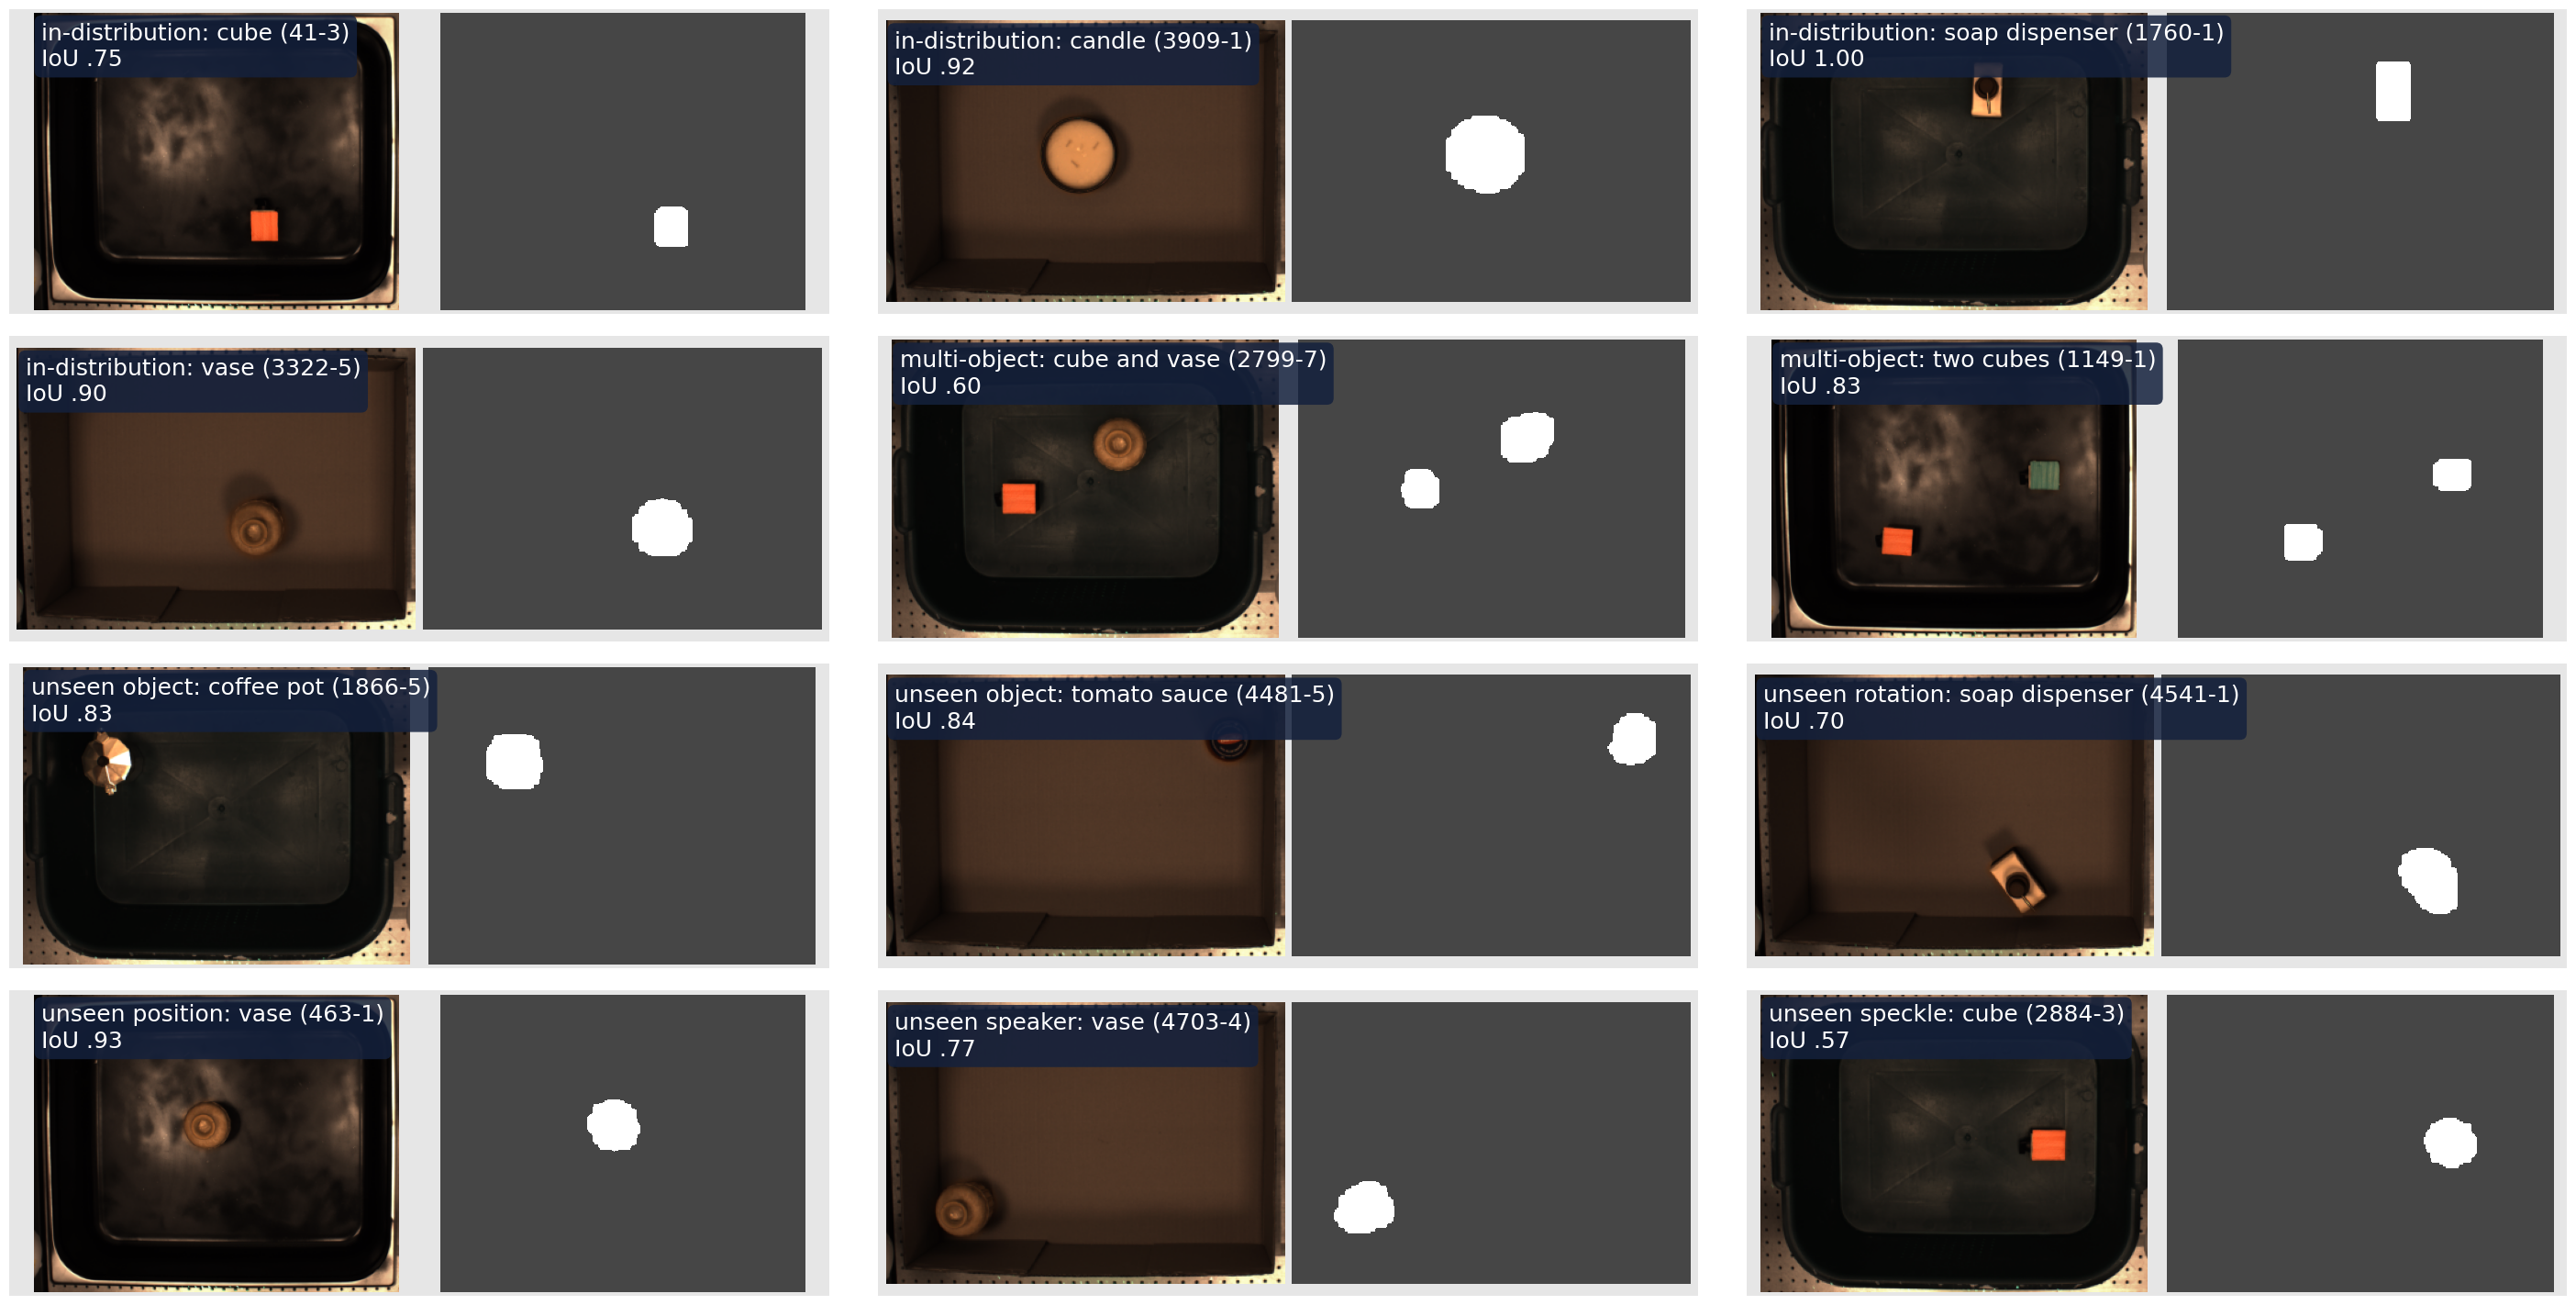

In [7]:
def tag(ax, text, H, W):
    """sample tag at the photo's top-left (data coords): white on a navy rounded box, TAG_FS pt, never clipped (a long label runs past the photo)"""
    ax.text(0.02 * W, 0.03 * H, text, ha="left", va="top", fontsize=TAG_FS, color="white", linespacing=1.25, clip_on=False, zorder=10,
            bbox=dict(boxstyle="round,pad=0.3", fc="#14213d", alpha=0.85, lw=0))

def obj_photo(name):
    """reference photo for an object name: OBJ_DIR/<name>.(png|jpg|jpeg), name lowercased with spaces / underscores -> '-'; None if there is none.
    -> RGBA float cropped to the object. If the file has no real alpha, the background = pixels within THUMB_TOL of the median border colour that
    are connected to the image border (so light parts inside the object stay), alpha feathered 1 px"""
    stem = name.lower().replace(" ", "-").replace("_", "-")
    f = next((ROOT / OBJ_DIR / f"{stem}{e}" for e in (".png", ".jpg", ".jpeg") if (ROOT / OBJ_DIR / f"{stem}{e}").exists()), None)
    if f is None: return None
    im = np.asarray(Image.open(f).convert("RGBA"), np.float32) / 255
    if im[..., 3].min() > 0.99:                                                    # opaque: cut the background out
        rgb = im[..., :3]
        edge = np.concatenate([rgb[0], rgb[-1], rgb[:, 0], rgb[:, -1]])
        near = np.linalg.norm(rgb - np.median(edge, 0), axis=-1) < THUMB_TOL
        lab, _ = ndimage.label(near)
        bg = np.isin(lab, np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))) & near
        im[..., 3] = np.clip(ndimage.gaussian_filter((~bg).astype(np.float32), 1.0), 0, 1) * ~ndimage.binary_erosion(bg, iterations=1)
    r, c = np.nonzero(im[..., 3] > 0.05)
    return im[r.min():r.max() + 1, c.min():c.max() + 1] if len(r) else None

def thumbs(img, objs, pad=0.03):
    """img (H,W,3) uint8 with each object's reference photo alpha-composited in the bottom-right corner, height THUMB_FRAC * H, side by side leftward;
    no backing, no border; objects without a photo are skipped, and an object that would leave the photo is dropped"""
    out = img.astype(np.float32) / 255; H, W = out.shape[:2]
    th, x1, y1 = round(THUMB_FRAC * H), round(W * (1 - pad)), round(H * (1 - pad))
    for o in objs:
        im = obj_photo(o)
        if im is None: continue
        tw = round(th * im.shape[1] / im.shape[0])
        if x1 - tw < 0: break
        im = np.asarray(Image.fromarray((im * 255).astype(np.uint8)).resize((tw, th), Image.LANCZOS), np.float32) / 255
        al = im[..., 3:]
        out[y1 - th:y1, x1 - tw:x1] = out[y1 - th:y1, x1 - tw:x1] * (1 - al) + im[..., :3] * al
        x1 -= tw + round(pad * W)
    return (out * 255).astype(np.uint8)

def cell(ax):
    """every cell the same box: transparent face (the sample's SAMPLE_BG card shows in the letterbox margins), no ticks / spines; image letterboxed at its true aspect"""
    ax.set_aspect("equal", adjustable="datalim"); ax.set_anchor("C"); ax.set_facecolor("none")
    ax.set_xticks([]); ax.set_yticks([]); [sp.set_visible(False) for sp in ax.spines.values()]

def pairs(d, h=3.2, cell_aspect=1.35, card_pad=0.003):
    """figure from the files in d only (samples.csv + <stem>_{true,pred}.png): per sample GT photo (+ reference photos of its true objects if SHOW_THUMBS) | predicted mask, tag "<label> (<id>) / IoU"
    on the photo, N_PER_ROW pairs per row in csv order. All cells the same size (h tall, h * cell_aspect wide), images letterboxed at their aspect
    on a SAMPLE_BG card per sample (card_pad in figure fractions around the pair)"""
    d = Path(d); T = pd.read_csv(d / "samples.csv")
    n_rows = -(-len(T) // N_PER_ROW)
    fig = plt.figure(figsize=(h * cell_aspect * 2 * N_PER_ROW * 1.08, h * n_rows * 1.1))
    outer = fig.add_gridspec(n_rows, N_PER_ROW, wspace=0.08, hspace=0.1, left=0.005, right=0.995, top=0.995, bottom=0.005)
    for k, r in enumerate(T.itertuples()):
        cellspec = outer[k // N_PER_ROW, k % N_PER_ROW]
        bb = cellspec.get_position(fig)                                            # one card per sample behind both cells and the gap between them
        fig.add_artist(plt.Rectangle((bb.x0 - card_pad, bb.y0 - card_pad), bb.width + 2 * card_pad, bb.height + 2 * card_pad,
                                     transform=fig.transFigure, fc=SAMPLE_BG, ec="none", zorder=-1))
        sub = cellspec.subgridspec(1, 2, wspace=0.02)
        a, b = fig.add_subplot(sub[0]), fig.add_subplot(sub[1])
        true, pred = (np.asarray(Image.open(d / f"{r.stem}_{x}.png")) for x in ("true", "pred"))
        a.imshow(thumbs(true, str(r.object).split("+")) if SHOW_THUMBS else true); b.imshow(pred, interpolation="nearest")
        cell(a); cell(b)
        a.set_zorder(3)                                                            # the photo (and its tag) above the mask cell, so a long tag is not hidden
        tag(a, f"{r.label} ({r.id})\nIoU {f'{r.iou:.2f}'.lstrip('0')}", *true.shape[:2])
    return fig

for r in pd.read_csv(OUTD / "samples.csv").itertuples():   # which true objects have a reference photo
    print(f"{r.id:8s} {r.label:16s}", {o: (obj_photo(o) is not None) for o in str(r.object).split("+")})
fig = pairs(OUTD)
fig.savefig(PLOTS / f"nb134_pairs.svg", dpi=400, bbox_inches="tight")
plt.show()